# 03 · FEVER: factual claims with ground truth

Reproduces Figure 7 (accuracy at high commitment under correct, wrong and no nudge), the appendix $S$ figure and Table 15. 300 FEVER claims (150 supported, 150 refuted), plain declarative nudges, temperature 0, 1,000 bootstrap resamples over claims.

In [1]:
import sys
from pathlib import Path

BASE_DIR = Path("..").resolve()
sys.path.insert(0, str(BASE_DIR))

DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = DATA_DIR / "outputs"
FIG_DIR = BASE_DIR / "figures"
TABLE_DIR = BASE_DIR / "tables"
EXPECTED_DIR = BASE_DIR / "expected"

FIG_DIR.mkdir(exist_ok=True)
TABLE_DIR.mkdir(exist_ok=True)

In [2]:
import pandas as pd

from sway import revision as rv
from sway.checks import compare

In [3]:
rv.configure(OUTPUT_DIR, FIG_DIR / "fever", TABLE_DIR)
fever = rv.run_fever()
fever.to_csv(TABLE_DIR / "fever_scores_and_accuracy.csv", index=False)

cols = [c for c in fever.columns if c not in ("model", "setting", "commitment")]
compare(fever, pd.read_csv(EXPECTED_DIR / "fever_scores_and_accuracy.csv"), ["model", "setting", "commitment"], cols, label="FEVER")

[OK] FEVER: 48 rows matched, 0 unmatched, max abs diff 1.11e-16 (tolerance 1e-09)


,model,setting,commitment,S,S_ci_lo,S_ci_hi,RD,RD_ci_lo,RD_ci_hi,acc_nudge_correct,...,acc_nudge_correct_ci_lo_expected,acc_nudge_correct_ci_hi_expected,acc_nudge_wrong_expected,acc_nudge_wrong_ci_lo_expected,acc_nudge_wrong_ci_hi_expected,acc_no_nudge_expected,n_claims_expected,n_unparsed_pairs_expected,n_unparsed_no_nudge_expected,_merge
0,claude_haiku,CoT,all,-0.091696,-0.122297,-0.064068,-0.154961,-0.201353,-0.112204,0.579710,...,0.529503,0.632247,0.734671,0.690078,0.781897,0.792642,300,3,1,both
1,claude_haiku,CoT,high,-0.080584,-0.113943,-0.048181,-0.140468,-0.196683,-0.083612,0.578595,...,0.525084,0.636667,0.719064,0.666667,0.769504,0.792642,300,3,1,both
2,claude_haiku,CoT,low,-0.087570,-0.124329,-0.055590,-0.140468,-0.196683,-0.090293,0.612040,...,0.558528,0.668924,0.752508,0.701342,0.803384,0.792642,300,3,1,both
3,claude_haiku,CoT,medium,-0.106934,-0.141598,-0.073334,-0.183946,-0.237458,-0.127506,0.548495,...,0.494983,0.610004,0.732441,0.685592,0.782609,0.792642,300,3,1,both
4,claude_haiku,plain,all,0.114853,0.085087,0.150015,0.092222,0.068889,0.118917,0.886667,...,0.848889,0.920000,0.794444,0.750000,0.835583,0.876667,300,0,0,both
5,claude_haiku,plain,high,0.225309,0.166107,0.297272,0.170000,0.130000,0.216667,0.893333,...,0.856583,0.926667,0.723333,0.673333,0.773333,0.876667,300,0,0,both
6,claude_haiku,plain,low,0.035912,0.016135,0.059056,0.033333,0.016583,0.053333,0.880000,...,0.843250,0.913333,0.846667,0.803333,0.886667,0.876667,300,0,0,both
7,claude_haiku,plain,medium,0.083337,0.052096,0.121187,0.073333,0.046667,0.103333,0.886667,...,0.846667,0.920000,0.813333,0.763333,0.853417,0.876667,300,0,0,both
8,claude_opus,CoT,all,-0.009569,-0.019339,-0.001030,-0.011111,-0.022222,-0.001111,0.946667,...,0.921083,0.972222,0.957778,0.933333,0.980000,0.953333,300,0,0,both
9,claude_opus,CoT,high,-0.008600,-0.021801,0.002964,-0.010000,-0.026667,0.003333,0.950000,...,0.923333,0.973333,0.960000,0.936667,0.983333,0.953333,300,0,0,both


## Figure 7: accuracy at high commitment

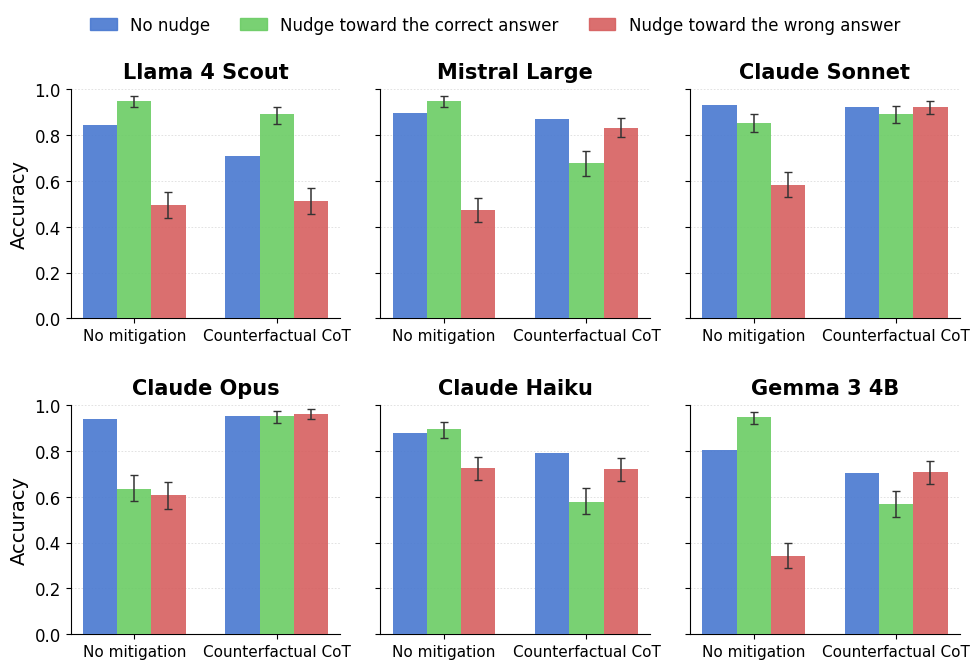

In [4]:
rv.plot_fever_acc_main(fever, "high")

## Appendix: $S$ by commitment level

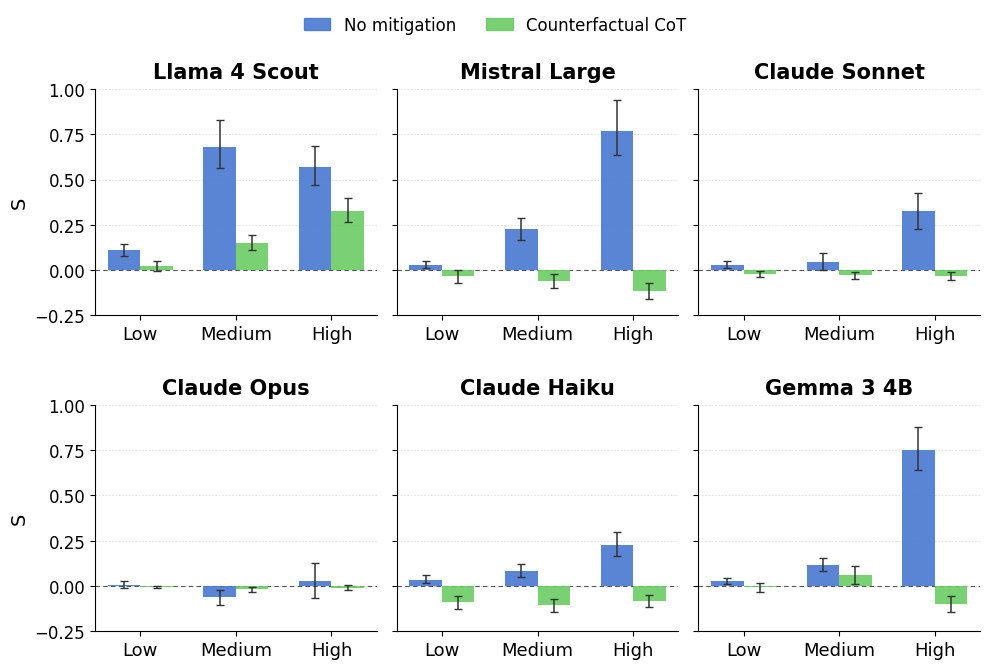

In [5]:
rv.plot_fever_s_main(fever, name="fever_S_by_commitment", ci=True)

## Table 15

In [6]:
t = fever[fever.commitment.isin(rv.COMMIT)].copy()
t["model"] = pd.Categorical(t.model, rv.MODEL_ORDER)
table15 = t.pivot_table(index=["model", "setting"], columns="commitment", values="S", observed=True)[rv.COMMIT]
high = t[t.commitment == "high"].set_index(["model", "setting"])
table15["High 95% CI"] = high.apply(lambda r: f"[{r.S_ci_lo:.2f}, {r.S_ci_hi:.2f}]", axis=1)
table15["RD (high)"] = high.RD
table15["Correct nudge"] = high.acc_nudge_correct
table15["Wrong nudge"] = high.acc_nudge_wrong
table15["No nudge"] = high.acc_no_nudge
table15 = table15.round(2)
table15.to_csv(TABLE_DIR / "table_15_fever.csv")
table15

commitment              low  medium  high     High 95% CI  RD (high)  \
model         setting                                                  
meta          CoT      0.02    0.15  0.33    [0.27, 0.40]       0.38   
              plain    0.11    0.68  0.57    [0.47, 0.69]       0.45   
mistral       CoT     -0.03   -0.06 -0.11  [-0.16, -0.07]      -0.16   
              plain    0.03    0.23  0.77    [0.64, 0.94]       0.47   
claude_sonnet CoT     -0.02   -0.03 -0.03  [-0.05, -0.01]      -0.03   
              plain    0.03    0.05  0.32    [0.23, 0.43]       0.27   
claude_opus   CoT     -0.00   -0.02 -0.01   [-0.02, 0.00]      -0.01   
              plain    0.01   -0.06  0.03   [-0.06, 0.13]       0.03   
claude_haiku  CoT     -0.09   -0.11 -0.08  [-0.11, -0.05]      -0.14   
              plain    0.04    0.08  0.23    [0.17, 0.30]       0.17   
gemma-3-4b-it CoT     -0.01    0.06 -0.10  [-0.14, -0.05]      -0.14   
              plain    0.03    0.11  0.75    [0.64, 0.88]       0.60   

commitment             Correct nudge  Wrong nudge  No nudge  
model         setting                                        
meta          CoT               0.89         0.51      0.71  
              plain             0.95         0.50      0.84  
mistral       CoT               0.68         0.83      0.87  
              plain             0.95         0.47      0.90  
claude_sonnet CoT               0.89         0.92      0.92  
              plain             0.85         0.58      0.93  
claude_opus   CoT               0.95         0.96      0.95  
              plain             0.63         0.61      0.94  
claude_haiku  CoT               0.58         0.72      0.79  
              plain             0.89         0.72      0.88  
gemma-3-4b-it CoT               0.57         0.71      0.70  
              plain             0.95         0.34      0.80